# 1.2 Хүний мэдрэхүйн онцлогийг ашиглах

**Сценари:** 4 төрлийн бараа (A, B, C, D) × 3 улирал (Өвөл, Хавар, Зун) борлуулалтын өгөгдөл.

**3 харааны суваг:**

| Суваг | Юуг кодлох | Demo |
|---|---|---|
| **Өнгө (hue)** | Улирал | Demo 1 |
| **Хэлбэр (marker)** | Бараа төрөл | Demo 2 |
| **Хэмжээ (size)** | Борлуулалтын дүн | Demo 3 |

Суваг бүрийг шалтгаанаараа тайлбарлан, тус тусад нь дэмо-графикаар харуулав.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

# ── Өгөгдөл: 4 бараа × 3 улирал ──
products = ['A', 'B', 'C', 'D']
seasons  = ['Өвөл', 'Хавар', 'Зун']

sales = {
    'Өвөл':  {'A': 120, 'B': 85,  'C': 60,  'D': 200},
    'Хавар': {'A': 95,  'B': 140, 'C': 110, 'D': 75},
    'Зун':   {'A': 70,  'B': 180, 'C': 155, 'D': 50},
}

# Улирлын өнгө (Demo 1), Барааны хэлбэр (Demo 2)
season_colors   = {'Өвөл': '#4B9CD3', 'Хавар': '#6ABF69', 'Зун': '#E87722'}
product_markers = {'A': 'o', 'B': 's', 'C': '^', 'D': 'D'}

print('Өгөгдөл бэлэн:', len(products)*len(seasons), 'мөр')

Өгөгдөл бэлэн: 12 мөр


## Demo 1 — Өнгөний схем (улирлыг илэрхийлэх)

Улирал нь **категор** утга тул тоо-пропорциональ (sequential) биш, **qualitative palette** хэрэглэнэ.

- `Өвөл → #4B9CD3` **цэнхэр** — хүйтний сэтгэлзүйн холбоо
- `Хавар → #6ABF69` **ногоон** — сэргэлт, ургалтын дохио
- `Зун → #E87722` **улбар** — дулаан, идэвх

3 өнгө нь хоорондоо өндөр ялгаатай, улаан/ногоон хослолгүй → өнгө сохорт ч аймаар.

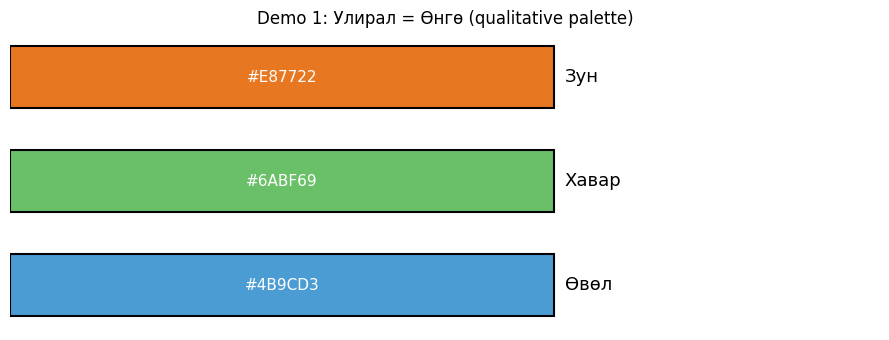

In [2]:
# Demo 1: Улирлын өнгөний схем — тусдаа харуулсан өнгөний суваг
fig, ax = plt.subplots(figsize=(9, 3.5))
y = np.arange(len(seasons))

for yi, season in enumerate(seasons):
    ax.barh(yi, 1, color=season_colors[season], height=0.6, edgecolor='black', linewidth=1.5)
    ax.text(1.02, yi, season, va='center', fontsize=13)
    ax.text(0.5, yi, season_colors[season], va='center', ha='center', color='white', fontsize=11)

ax.set_xlim(0, 1.6); ax.set_yticks([]); ax.set_title('Demo 1: Улирал = Өнгө (qualitative palette)', fontsize=12)
ax.axis('off')
plt.tight_layout(); plt.show()

**Шалтгаан:**
- **Pre-attentive суваг:** үзэгч графикаа уншихгүйгээр өнгөөр шууд ялгана.
- Улирал эрэмбэлэгдсэн (ordinal) ч гэсэн 3-хан түвшин тул sequential colormap ашиглах шаардлагагүй; тод 3 qualitative өнгө илүү шигдэнэ.
- `#4B9CD3/#6ABF69/#E87722` нь Red-Green хамааралгүй тул өнгө сохорт хэсэгчилсэн хэрэглэгчдэд ч тусдаа.

## Demo 2 — Хэлбэрийн сонголт (бараа төрлийг ялгах)

Барааны төрөл = 4 категорийн тул **4 өөр геометр маркер** хэрэглэнэ. Энд **өнгөнөөс үл хамааран зөвхөн хэлбэрээр** ялгахыг харуулж байна:

| Бараа | Маркер | Утга |
|---|---|---|
| A | `o` тойрог | суурь, энгийн бараа |
| B | `s` дөрвөлжин | хоёрдогч бараа |
| C | `^` гурвалжин | өсөлтийн дохио |
| D | `D` ромб | онцгой, тусгай бараа |

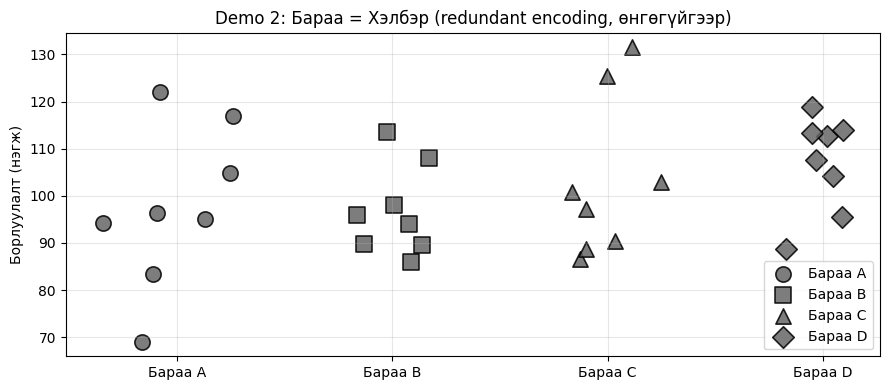

In [3]:
# Demo 2: Зөвхөн хэлбэрээр бараа ялгах (бүгд ижил саарал өнгө)
fig, ax = plt.subplots(figsize=(9, 4))
np.random.seed(1)
for i, prod in enumerate(products):
    xs = np.random.normal(i + 1, 0.15, 8)
    ys = np.random.normal(100, 15, 8)
    ax.scatter(xs, ys, marker=product_markers[prod], s=120, c='#666666',
               edgecolors='black', linewidths=1.2, alpha=0.85, label='Бараа ' + prod)

ax.set_xticks(np.arange(1, 5)); ax.set_xticklabels(['Бараа A', 'Бараа B', 'Бараа C', 'Бараа D'])
ax.set_ylabel('Борлуулалт (нэгж)')
ax.set_title('Demo 2: Бараа = Хэлбэр (redundant encoding, өнгөгүйгээр)', fontsize=12)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Шалтгаан:**
- **Илүүдэл (redundant) кодчилол:** хэлбэр нь өнгөнөөс тусдаа суваг тул өнгө сохорт (~8%) хэрэглэгч алдагдахгүй.
- Кувмаркерууд `o s ^ D` нь бие биеэсээ хүчтэй ялгагдана (зөвхөн хэмжээ биш).
- Цолын утга симантик: тойрог = суурь, гурвалжин = өсөлт гэх мэт.

## Demo 3 — Хэмжээний стратеги (борлуулалтын хэмжээ)

Борлуулалт нь **тоон (quantitative)** утга тул цэгийн **талбай (area)**-гаар кодлод.

- `size = (утга / 200 × 30)²` — Matplotlib scatter-ийн `s` нь **талбай = r²**-д пропорциональ.
- Иймд утгад **sqrt** хэрэглэнэ: эс тэгвэл 200 vs 100 нь **4 дахин** том харагдах байсан (2× биш).

Доорх demo-д **хэмжээг бусад суваг нэмэлгүйгээр** ганцаар нь харуулж байна.

/var/folders/9z/_bgsb1152n9g37m6xn9h8thc0000gn/T/ipykernel_7450/1210149846.py:22: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


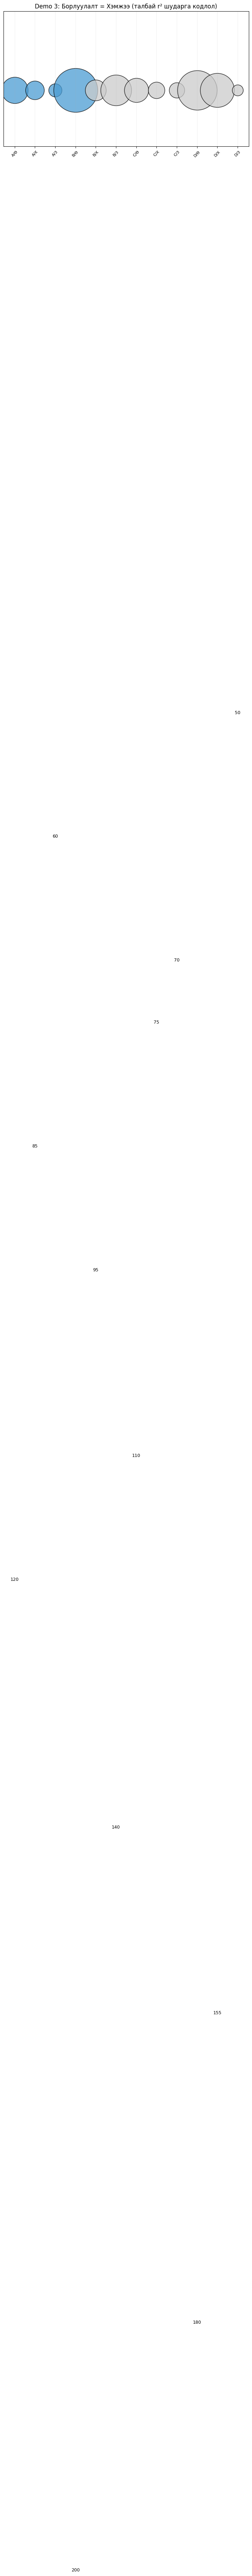

In [4]:
# Demo 3: Зөвхөн хэмжээгээр борлуулалтын дүнг кодлох (bubble)
fig, ax = plt.subplots(figsize=(9, 5))
xi = 0
for si, season in enumerate(seasons):
    for prod in products:
        s = sales[season][prod]
        ax.scatter(xi, 0.5, s=(s / 200 * 90) ** 2, c='#4B9CD3' if si == 0 else '#cccccc',
                   alpha=0.75, edgecolors='black', linewidths=1.2)
        ax.text(xi, 0.5 - (s / 200 * 22) - 0.04, f'{s}', ha='center', fontsize=9)
        xi += 1

# Солонго: утгын scale-ыг ойлгуулах
xtick = []
for prod in products:
    for season in seasons:
        xtick.append(f'{prod}/{season[0]}')
ax.set_xticks(range(len(xtick))); ax.set_xticklabels(xtick, rotation=45, fontsize=8)
ax.set_yticks([])
ax.set_ylim(0, 1.2)
ax.set_title('Demo 3: Борлуулалт = Хэмжээ (талбай r² шударга кодлол)', fontsize=12)
ax.grid(axis='x', alpha=0.2)
plt.tight_layout(); plt.show()

**Шалтгаан:**
- **Хэмжээ** нь тоон суваг тул "их = том, бага = жижиг" гэдэг нь зөн совинтой таарна.
- **Өргийн гажуудал сэргийлэх:** area-г утгад шууд пропорциональ биш, `sqrt`-ийн дараа-д тэнцүүлэнэ — математикийн хувьд зөв харьцаа.
- Хэмжээг зөвхөн борлуулалтад зориулах (tree бусад сувагт утгагүй) — суваг бүр нэг утга кодлох.

## Цогц — 3 суваг нэг графикт

Гурван суваг нэг графикт нэгтгэвэл өгөгдлийн бүх хэмжээсийн мэдээллийг нэг дороос уншина:

- **Өнгө** = улирал • **Хэлбэр** = бараа • **Хэмжээ** = борлуулалт • **Ирмэг** = давхцсан цэг ялгах

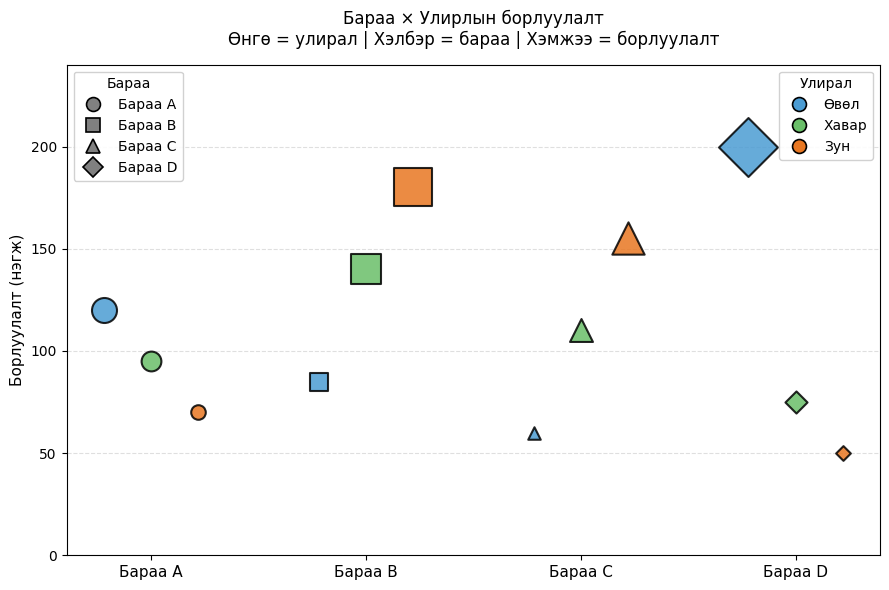

In [5]:
# Цогц график
def to_size(s):
    return (s / 200 * 30) ** 2

x_pos = {p: i + 1 for i, p in enumerate(products)}
fig, ax = plt.subplots(figsize=(9, 6))
for si, season in enumerate(seasons):
    for prod in products:
        s = sales[season][prod]
        ax.scatter(x_pos[prod] + (si - 1) * 0.22, s, s=to_size(s),
                   c=season_colors[season], marker=product_markers[prod],
                   edgecolors='black', linewidths=1.5, alpha=0.85, zorder=3)

ax.set_xticks(list(x_pos.values()))
ax.set_xticklabels([f'Бараа {p}' for p in products], fontsize=11)
ax.set_ylabel('Борлуулалт (нэгж)', fontsize=11)
ax.set_title('Бараа × Улирлын борлуулалт\nӨнгө = улирал | Хэлбэр = бараа | Хэмжээ = борлуулалт', fontsize=12, pad=14)
ax.set_ylim(0, 240); ax.grid(axis='y', linestyle='--', alpha=0.4)

leg1 = ax.legend(handles=[
    mlines.Line2D([], [], color=season_colors[s], marker='o', linestyle='None',
                  markersize=10, markeredgecolor='black', markeredgewidth=1.2, label=s)
    for s in seasons], title='Улирал', loc='upper right', framealpha=0.9)
ax.add_artist(leg1)

ax.legend(handles=[
    mlines.Line2D([], [], color='gray', marker=product_markers[p], linestyle='None',
                  markersize=10, markeredgecolor='black', markeredgewidth=1.2, label='Бараа ' + p)
    for p in products], title='Бараа', loc='upper left', framealpha=0.9)

plt.tight_layout(); plt.show()